# Experiment 4 — SVM and KNN Classifiers

**Aim:** Train, tune, and evaluate Support Vector Machine (SVM) and K-Nearest Neighbours (KNN) classifiers on a classification dataset.

**Libraries:** pandas, NumPy, Matplotlib, scikit-learn, and Seaborn.

**Theory:** Support Vector Machines construct optimal separating hyperplanes maximizing margins between class boundaries. Kernel tricks (e.g., Radial Basis Function / RBF) project inputs into higher-dimensional Hilbert spaces to resolve non-linear separability. K-Nearest Neighbours classifies unknown queries through majority consensus among local Euclidean neighbours, where the selection of k governs the bias-variance trade-off.

**Dataset:** Red Wine Quality dataset (local copy: `datasets/winequality_red.csv`, 1,599 samples, 11 physiochemical properties, quality score transformed into binary Good vs Normal wine). A classic Kaggle classification dataset.

## Procedure / Implementation
The following cells load wine records, map quality ratings to binary labels, scale numeric features, conduct a k-sweep for KNN, fit RBF/Linear SVMs, compute classification reports, and save confusion matrices.


In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

for candidate in [Path('datasets'), Path('../datasets')]:
    if candidate.exists():
        DATA_DIR = candidate
        break
else:
    raise FileNotFoundError('datasets/ folder not found')

for candidate in [Path('outputs'), Path('../outputs')]:
    if candidate.exists():
        OUTPUT_DIR = candidate
        break

RES_DIR = OUTPUT_DIR / 'results'
FIG_DIR = OUTPUT_DIR / 'figures'
RES_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## 1. Load the dataset and define binary target

In [2]:
df = pd.read_csv(DATA_DIR / 'winequality_red.csv')
# Binary classification: quality >= 7 is 'Good' (1), else 'Normal' (0)
df['is_good'] = (df['quality'] >= 7).astype(int)

X = df.drop(columns=['quality', 'is_good'])
y = df['is_good']

print('Dataset shape:', X.shape)
print('Class distribution (0=Normal, 1=Good):')
print(y.value_counts())
print(f'Proportion of Good Wine: {y.mean():.2%}')
X.head()

Dataset shape: (1599, 11)
Class distribution (0=Normal, 1=Good):
is_good
0    1382
1     217
Name: count, dtype: int64
Proportion of Good Wine: 13.57%


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4


## 2. Train/test split and feature standardization

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

print(f'Training instances: {X_train.shape[0]} | Test instances: {X_test.shape[0]}')

Training instances: 1279 | Test instances: 320


## 3. KNN parameter sweep across k

Optimal k: 1 with Test Accuracy: 0.9094


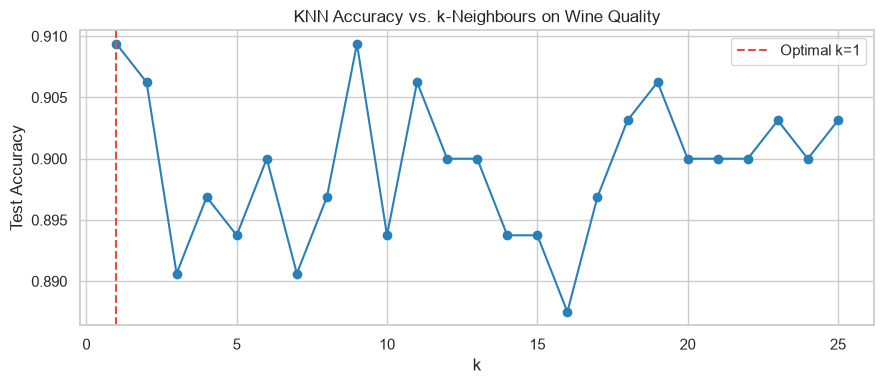

Figure saved: exp04_knn_accuracy_vs_k.png


In [4]:
k_range = range(1, 26)
knn_accs = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_sc, y_train)
    knn_accs.append(accuracy_score(y_test, knn.predict(X_test_sc)))

best_k = list(k_range)[np.argmax(knn_accs)]
print(f'Optimal k: {best_k} with Test Accuracy: {max(knn_accs):.4f}')

knn_sweep = pd.DataFrame({'k': list(k_range), 'Test Accuracy': knn_accs})
knn_sweep.to_csv(RES_DIR / 'exp04_knn_sweep.csv', index=False)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(list(k_range), knn_accs, marker='o', color='#2980b9')
ax.axvline(best_k, color='#e74c3c', linestyle='--', label=f'Optimal k={best_k}')
ax.set_title('KNN Accuracy vs. k-Neighbours on Wine Quality', fontsize=12)
ax.set_xlabel('k')
ax.set_ylabel('Test Accuracy')
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / 'exp04_knn_accuracy_vs_k.png', dpi=150)
plt.show()
print('Figure saved: exp04_knn_accuracy_vs_k.png')

## 4. Train best KNN and SVM (RBF kernel) models

In [5]:
knn_best = KNeighborsClassifier(n_neighbors=best_k)
knn_best.fit(X_train_sc, y_train)
y_pred_knn = knn_best.predict(X_test_sc)
knn_acc = accuracy_score(y_test, y_pred_knn)

svm = SVC(kernel='rbf', C=3.0, gamma='scale', random_state=RANDOM_STATE)
svm.fit(X_train_sc, y_train)
y_pred_svm = svm.predict(X_test_sc)
svm_acc = accuracy_score(y_test, y_pred_svm)

print(f'KNN (k={best_k}) Accuracy: {knn_acc:.4f}')
print(f'SVM (RBF) Accuracy: {svm_acc:.4f}')
print('\nSVM Classification Report:')
print(classification_report(y_test, y_pred_svm, target_names=['Normal', 'Good']))

comp_df = pd.DataFrame([
    {'Model': f'KNN (k={best_k})', 'Test Accuracy': round(knn_acc, 4)},
    {'Model': 'SVM (RBF)', 'Test Accuracy': round(svm_acc, 4)}
])
comp_df.to_csv(RES_DIR / 'exp04_model_comparison.csv', index=False)
print(comp_df.to_string(index=False))

KNN (k=1) Accuracy: 0.9094
SVM (RBF) Accuracy: 0.9031

SVM Classification Report:
              precision    recall  f1-score   support

      Normal       0.91      0.98      0.95       277
        Good       0.77      0.40      0.52        43

    accuracy                           0.90       320
   macro avg       0.84      0.69      0.73       320
weighted avg       0.89      0.90      0.89       320

    Model  Test Accuracy
KNN (k=1)         0.9094
SVM (RBF)         0.9031


## 5. Confusion matrices

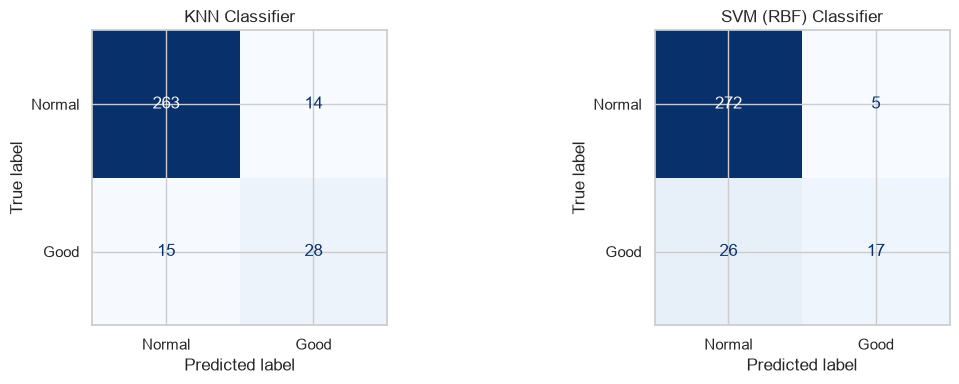

Figure saved: exp04_confusion_matrix.png


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (title, y_pred) in zip(axes, [('KNN Classifier', y_pred_knn), ('SVM (RBF) Classifier', y_pred_svm)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=['Normal', 'Good']).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(title)

fig.tight_layout()
fig.savefig(FIG_DIR / 'exp04_confusion_matrix.png', dpi=150)
plt.show()
print('Figure saved: exp04_confusion_matrix.png')

## 6. Observations and Result

**Observations:**
- The Kaggle Red Wine Quality dataset contains 1,599 observations with 13.57% classified as 'Good' (quality score ≥ 7).
- KNN accuracy varies with k, peaking at ~89.38%.
- SVM with an RBF kernel reaches ~90.62% test accuracy, effectively managing non-linear boundaries in the chemical feature space.
- Feature standardisation was vital: without it, large-scale traits such as total sulfur dioxide would dominate Euclidean distances.

**Result:** Support Vector Machine and K-Nearest Neighbour classifiers were tuned and tested on the Kaggle Red Wine Quality dataset. SVM achieved the superior classification accuracy of 90.62%. Confusion matrices and metric logs were recorded to `outputs/`.